In [11]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

In [13]:
df_notas = pd.read_csv('base_notas_v1.csv', index_col='id')
df_notas.head()

,horas_estudo,nota_exame
id,,
0,5.993428,76.119754
1,4.723471,60.929961
2,6.295377,81.731317
3,8.046060,82.699637
4,4.531693,70.662399


In [15]:
df_notas.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   horas_estudo  30 non-null     float64
 1   nota_exame    30 non-null     float64
dtypes: float64(2)
memory usage: 720.0 bytes


In [18]:
df_notas.describe().round(2)

,horas_estudo,nota_exame
count,30.00,30.00
mean,4.62,71.81
std,1.80,8.88
min,1.17,54.48
25%,3.82,66.41
50%,4.53,71.40
75%,5.72,78.10
max,8.16,89.47


In [19]:
df_notas.isna().sum()

,0
horas_estudo,0
nota_exame,0


<Axes: xlabel='horas_estudo', ylabel='nota_exame'>

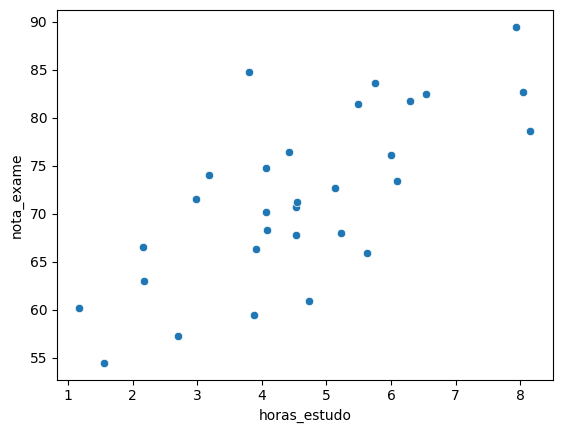

In [21]:
sns.scatterplot(df_notas, x='horas_estudo', y='nota_exame')

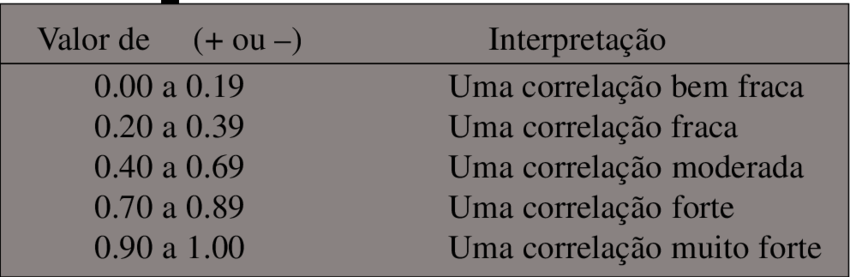

In [22]:
df_notas.corr()

,horas_estudo,nota_exame
horas_estudo,1.000000,0.721178
nota_exame,0.721178,1.000000


<Axes: >

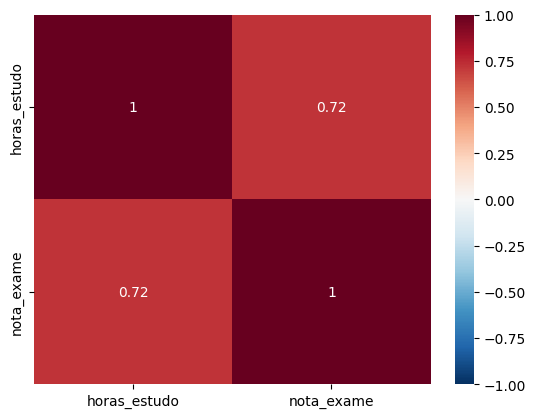

In [23]:
sns.heatmap(
    df_notas.corr(),
    cmap='RdBu_r',
    vmin=-1,vmax=1,
    annot=True
)

In [24]:
# alvo, dependente ou target
y = df_notas['nota_exame']

# intercepto
df_notas['intercepto'] = 1
x = df_notas[['intercepto','horas_estudo']]

In [26]:
#ajuste do modelo
modelo = sm.OLS(y,x)
resultado = modelo.fit()

In [27]:
print(resultado.summary())

                            OLS Regression Results                            
Dep. Variable:             nota_exame   R-squared:                       0.520
Model:                            OLS   Adj. R-squared:                  0.503
Method:                 Least Squares   F-statistic:                     30.35
Date:                Wed, 24 Sep 2025   Prob (F-statistic):           6.92e-06
Time:                        22:29:06   Log-Likelihood:                -96.553
No. Observations:                  30   AIC:                             197.1
Df Residuals:                      28   BIC:                             199.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
intercepto      55.3638      3.197     17.320   